# 1. Import library

In [1]:
import os
import random
import datetime
import pandas   as pd
import numpy    as np

from tqdm                       import tqdm
from preProcessingData          import PreProcessData
from utility.matpilotDraw       import MatPlot
from utility.config             import tepsConfig


# 2. Declare some parameters

In [2]:
plot               = MatPlot() 
case               = 5
# ----------------------    
# Reactor, Separator,Stripper
# ----------------------
# component  = "Separator"


np.random.seed(1)
random.seed(1)

preData    = PreProcessData(theCase=case)

# headline   = preData.reactorHeadline + preData.separatorHeadline + preData.stripperHeadline

headline        = preData.allHeadline
degraHeadline   = preData.degraLiq

Process:70739||2024-03-18 00:56:02,880-INFO [preProcessingData.py:__init__():78]:Loading data from files ...


# 3. Preprocessing the data

### a. Load data from files

In [3]:
# "all", "testAll",

rawData,rulLabel,time,degra  = preData.getDataset(  component       = "testAll",
                                                    removeInitState = True,
                                                    )    

drawID = 0
drawTime    = time[drawID]
drawData    = rawData[drawID]
drawRUL     = rulLabel[drawID]

Process:70739||2024-03-18 00:56:08,756-INFO [preProcessingData.py:getDataset():100]:Converting data to list of array ...


#### Draw Raw data

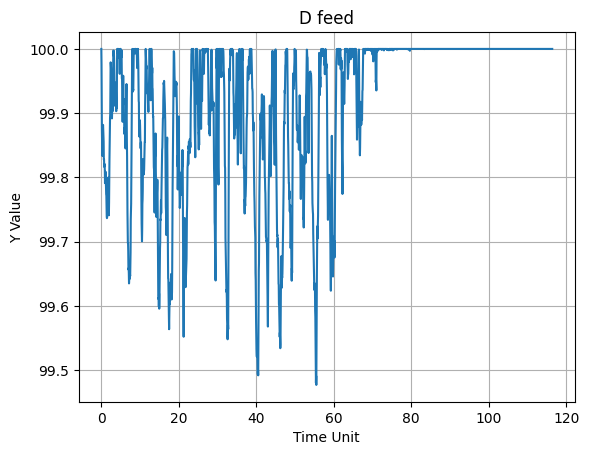

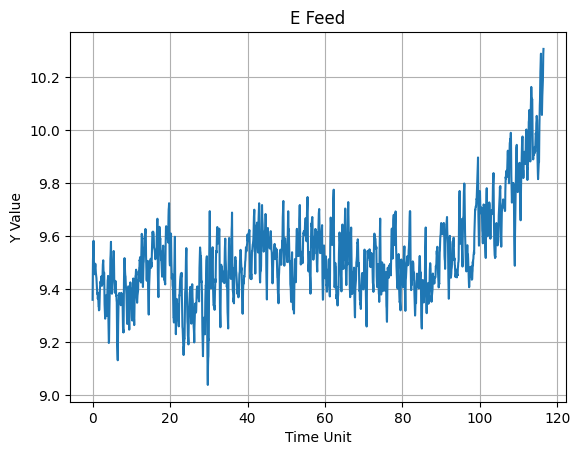

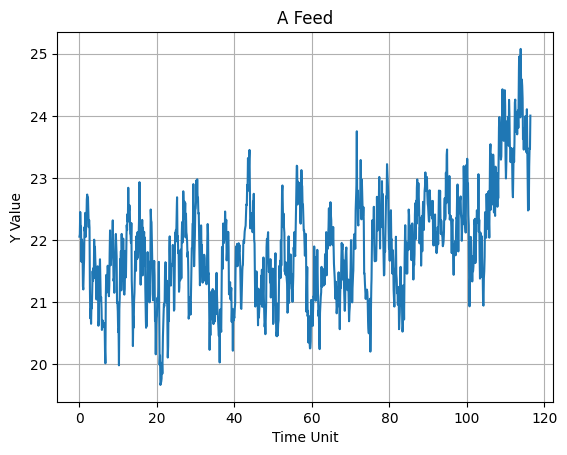

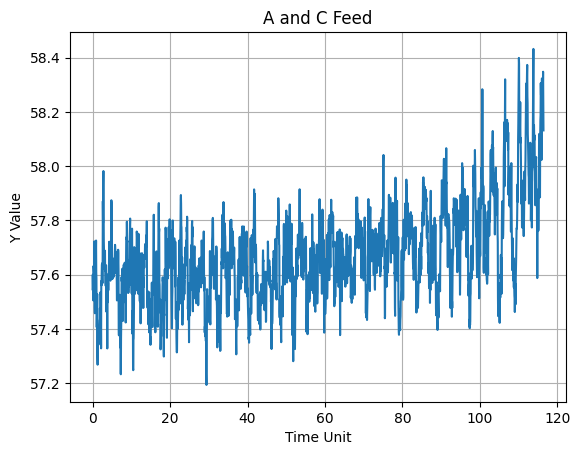

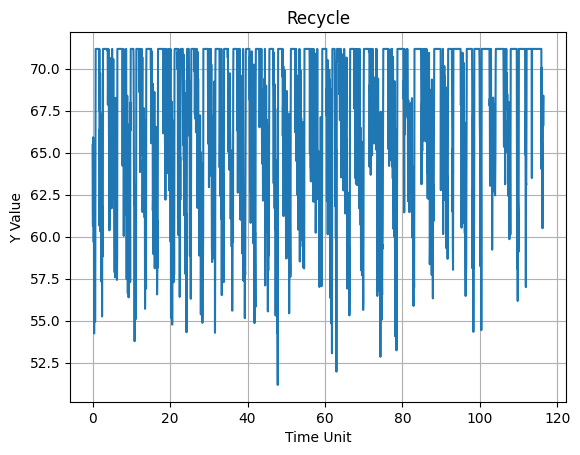

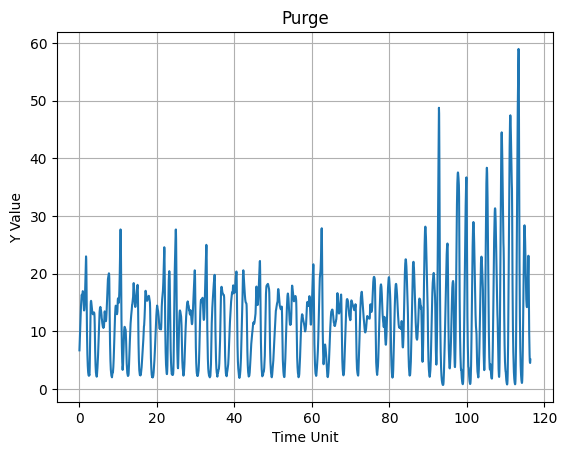

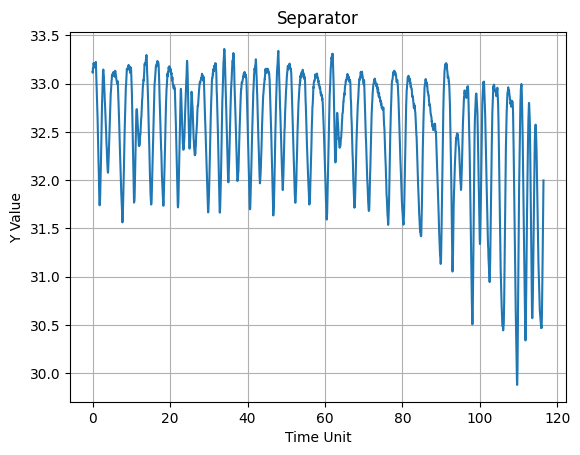

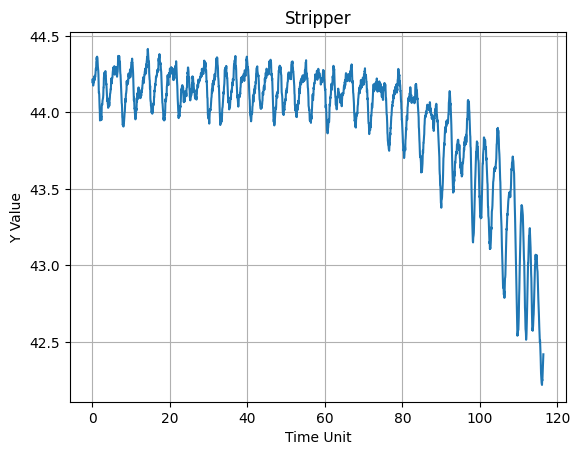

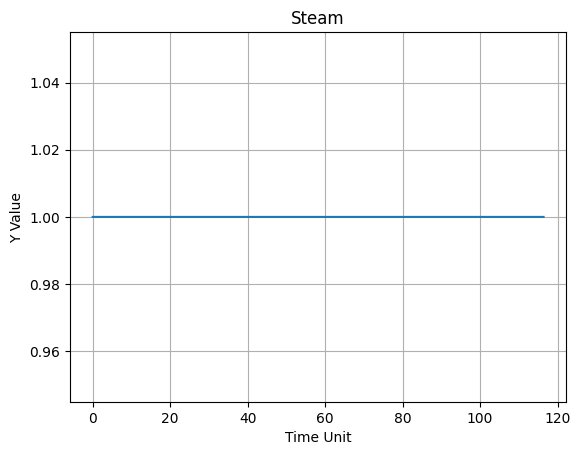

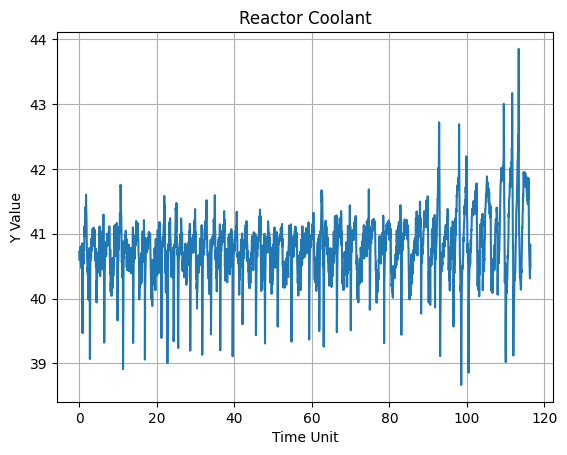

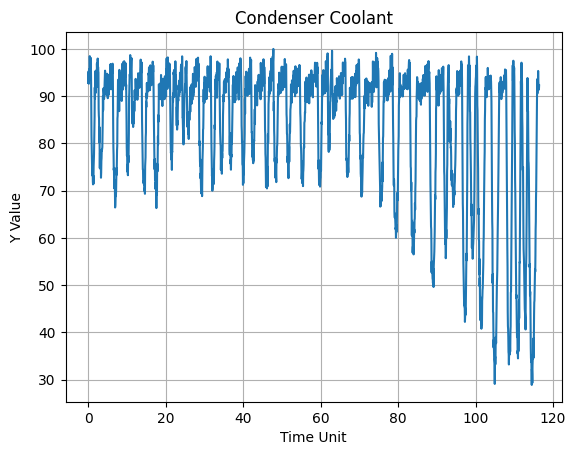

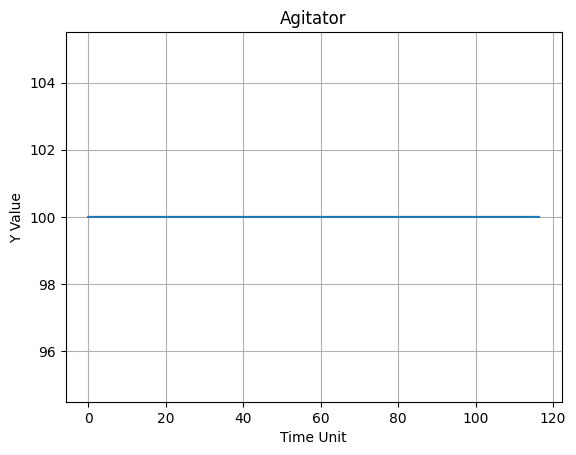

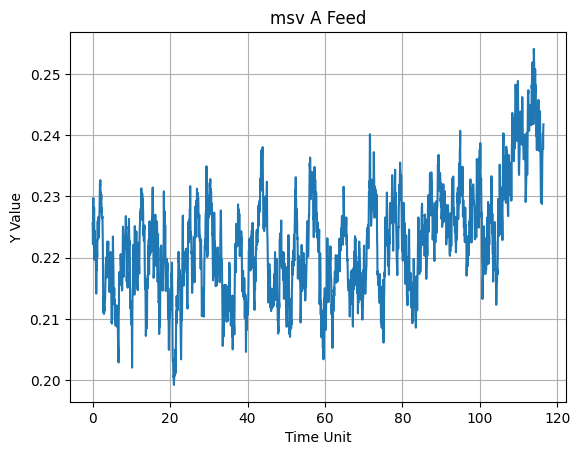

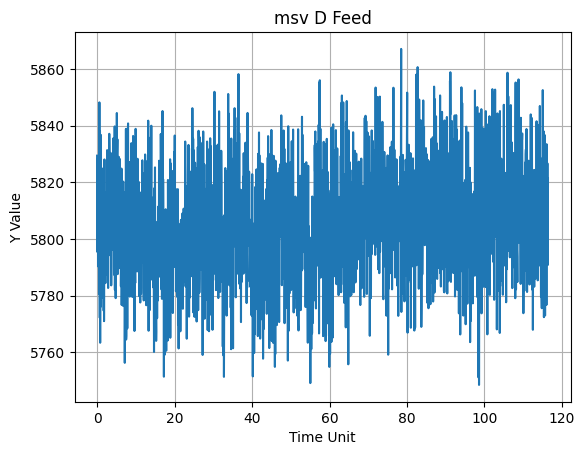

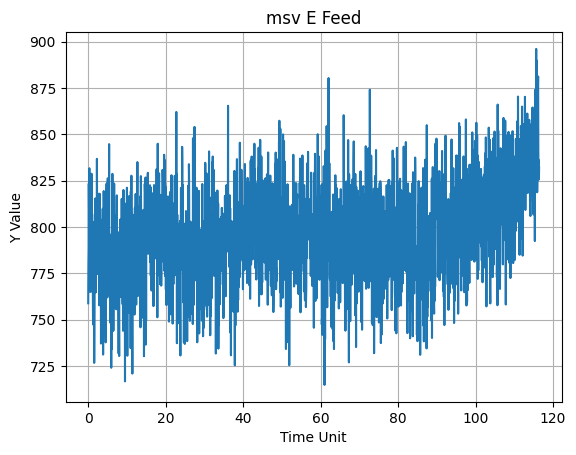

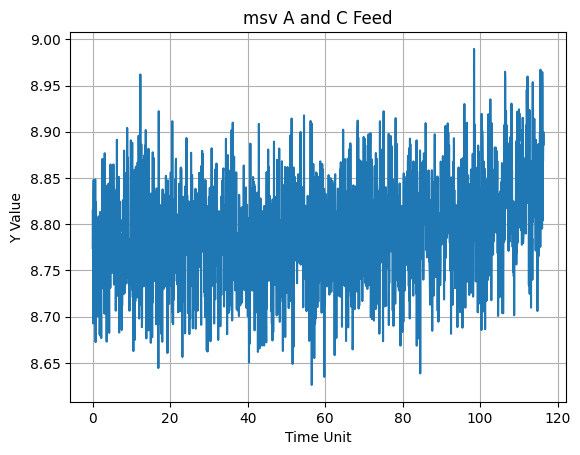

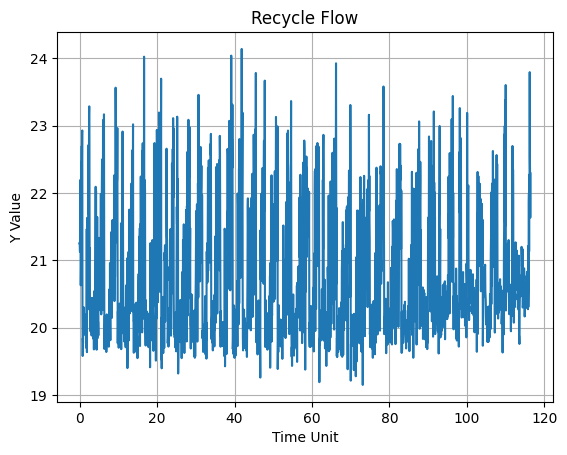

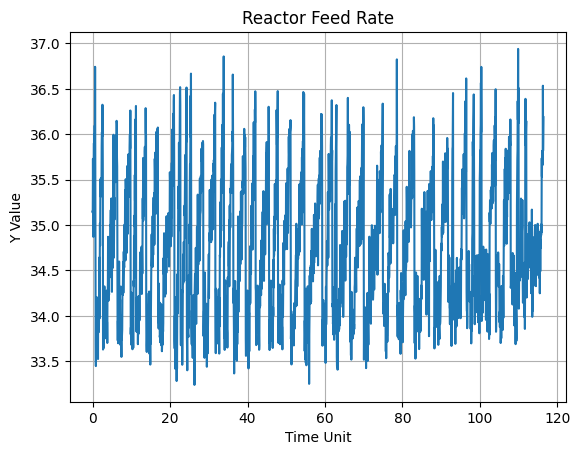

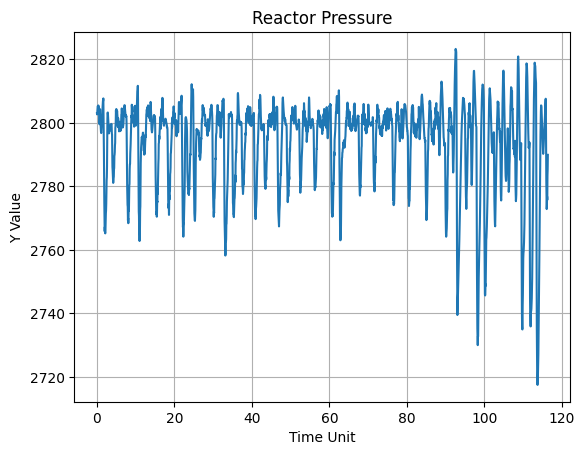

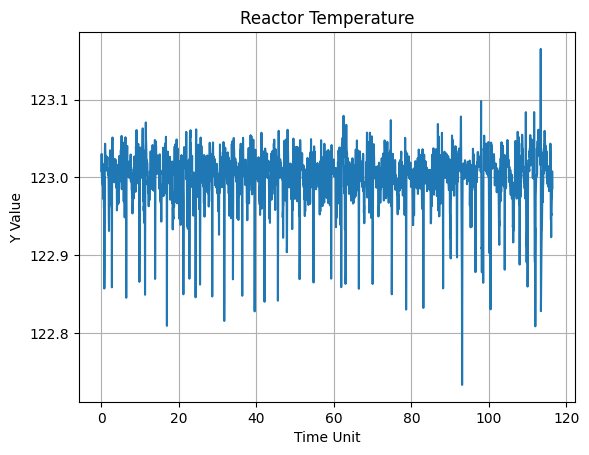

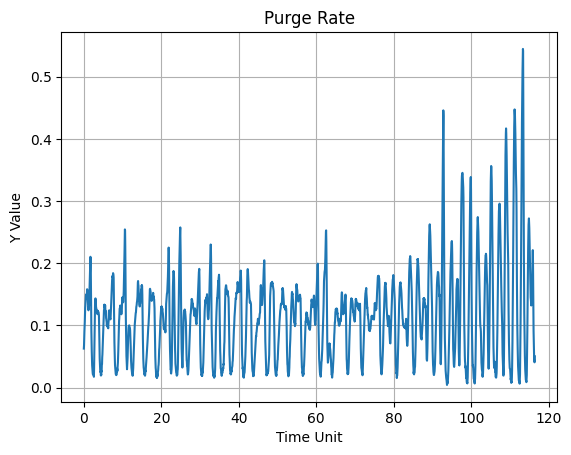

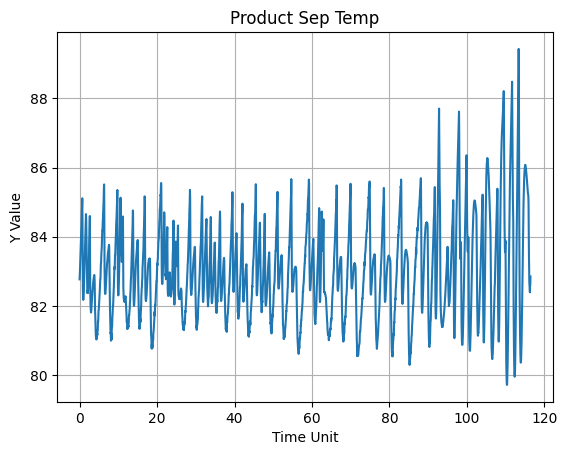

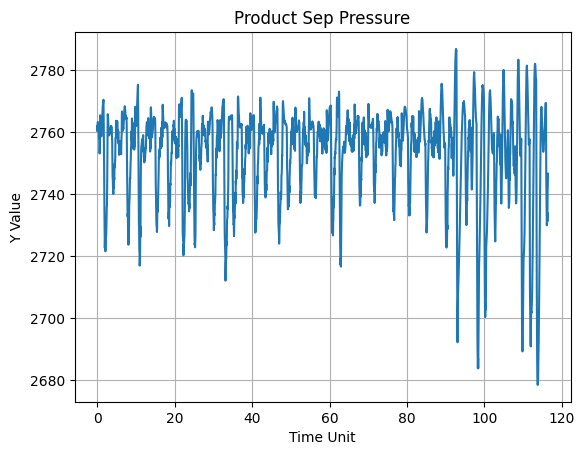

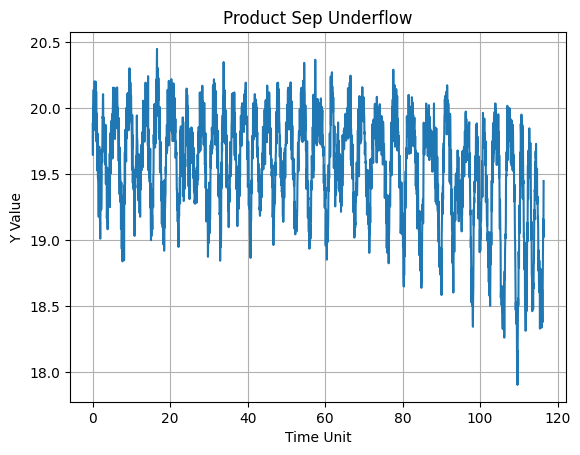

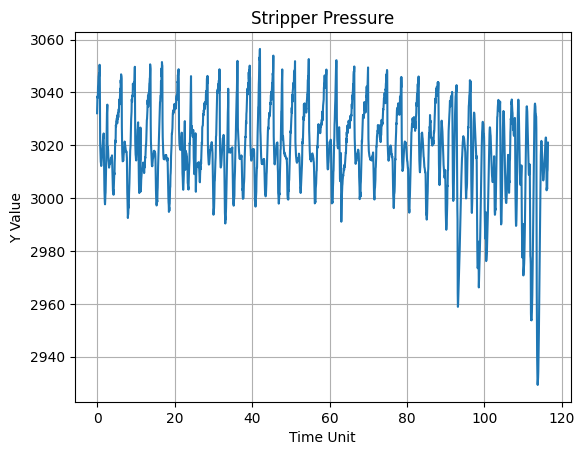

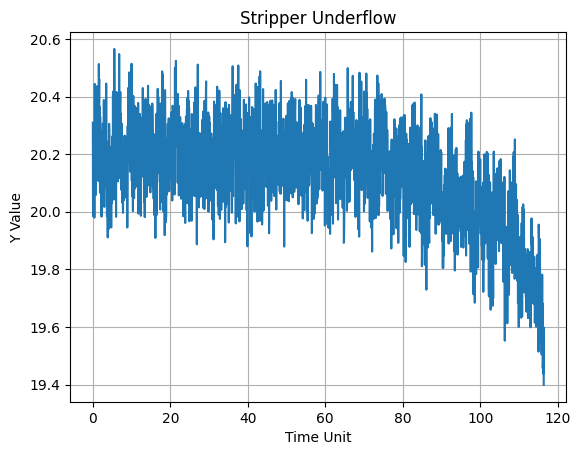

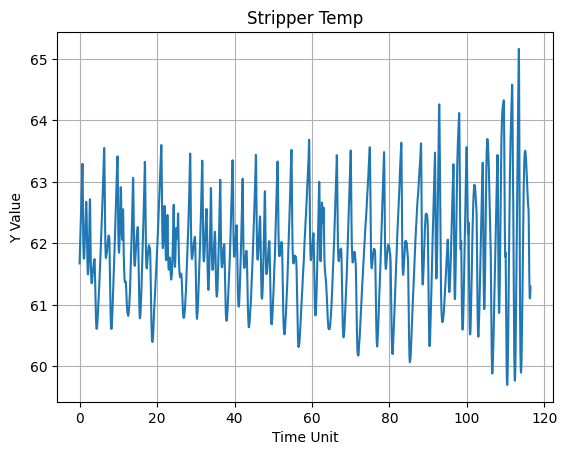

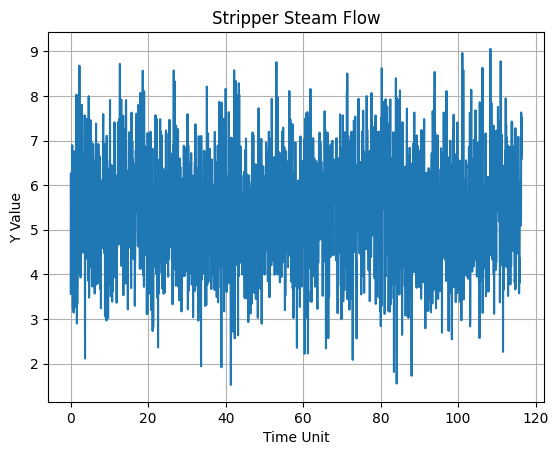

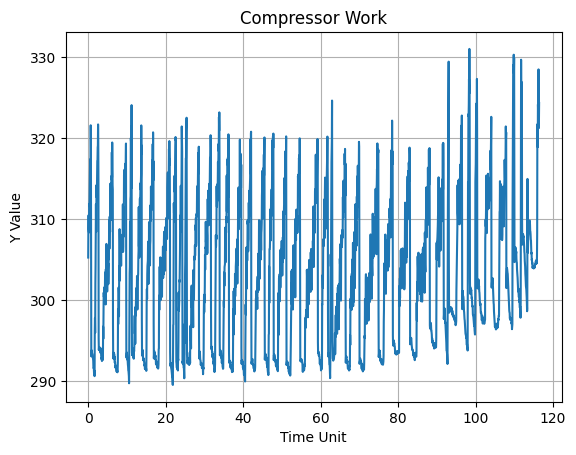

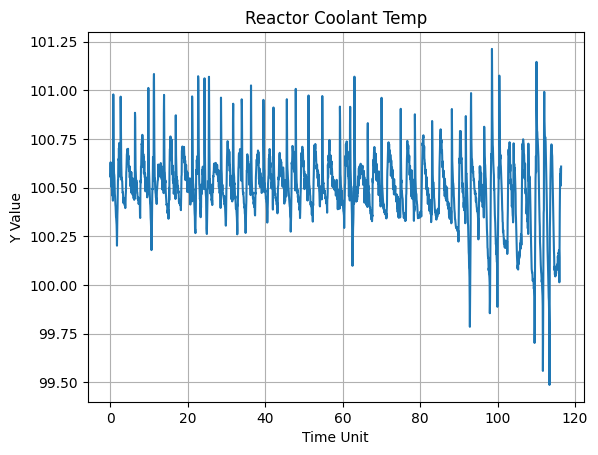

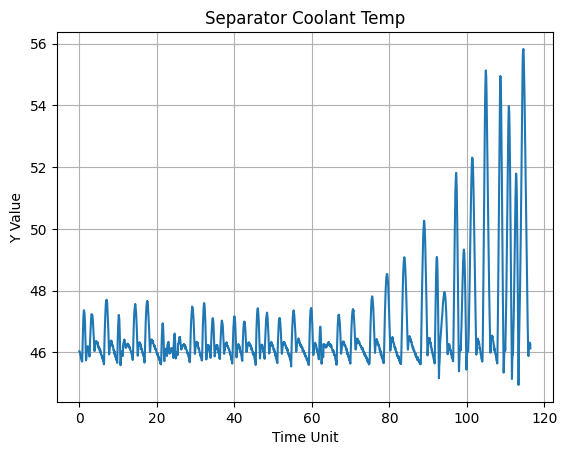

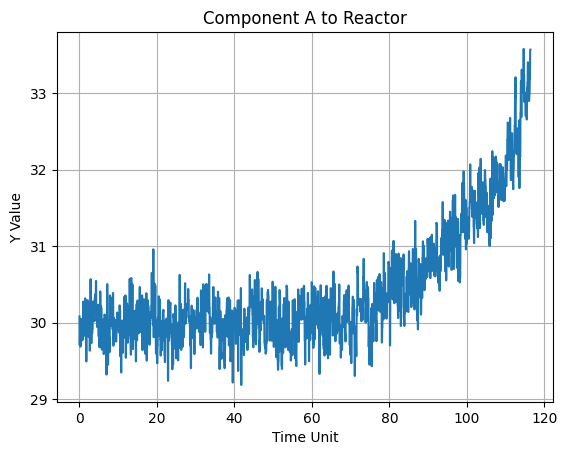

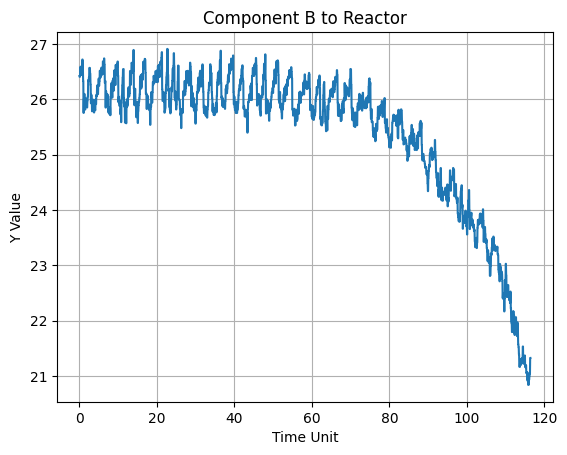

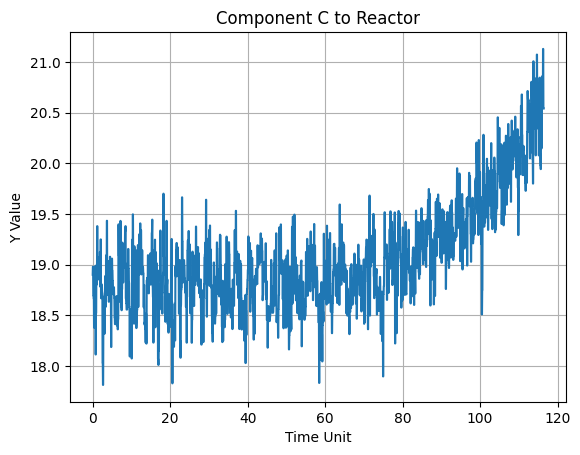

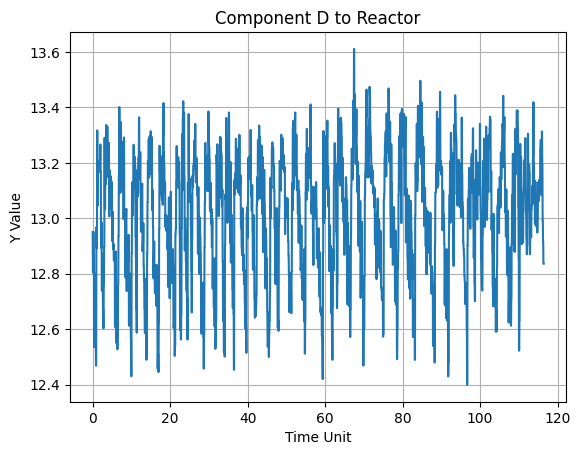

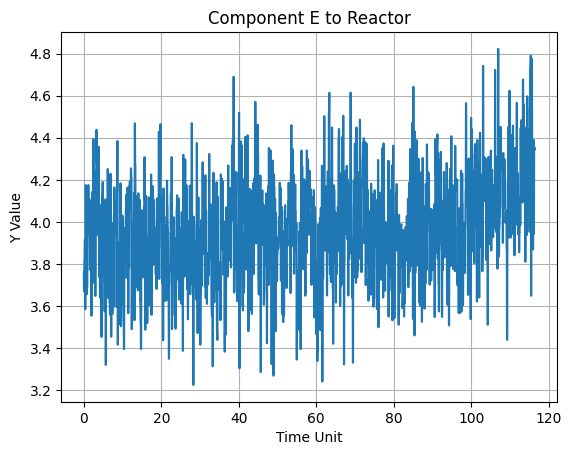

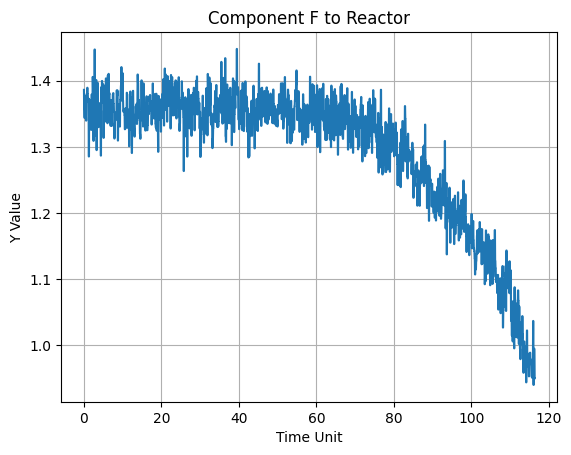

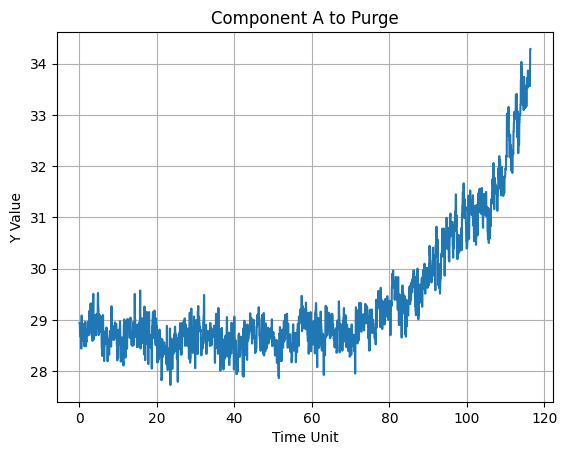

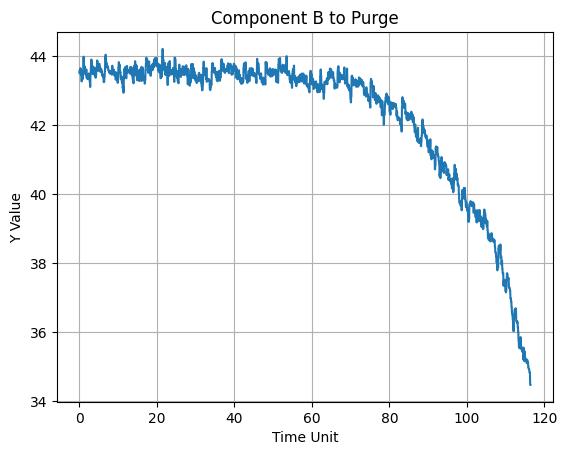

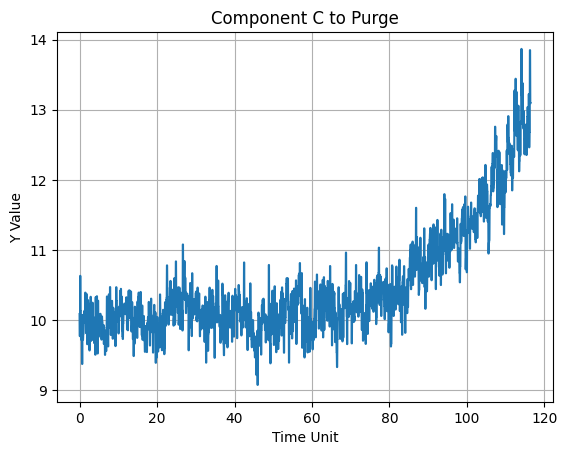

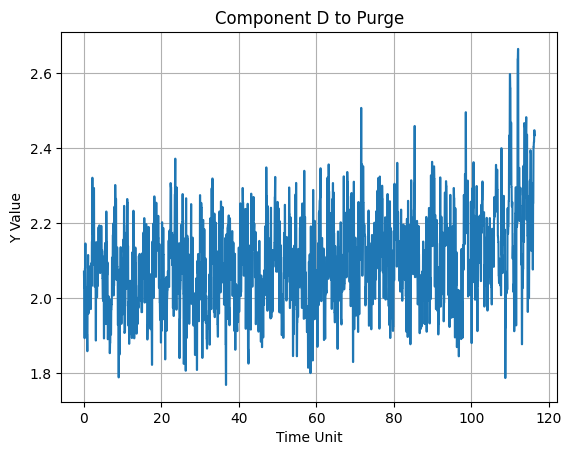

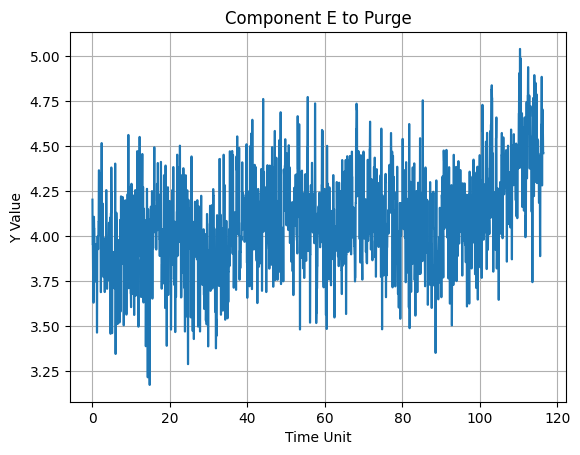

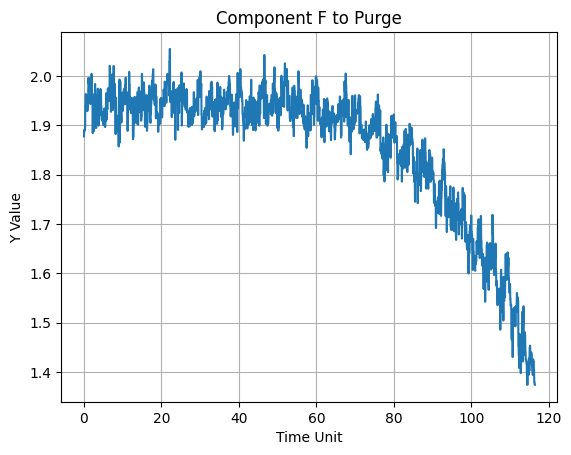

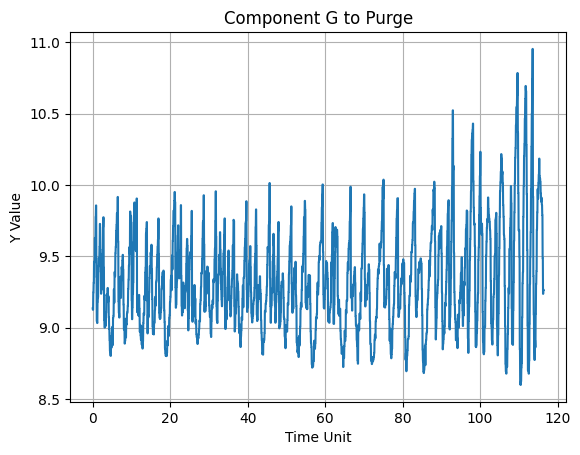

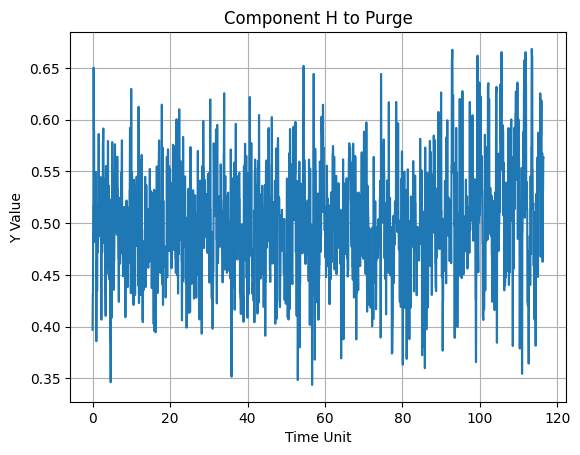

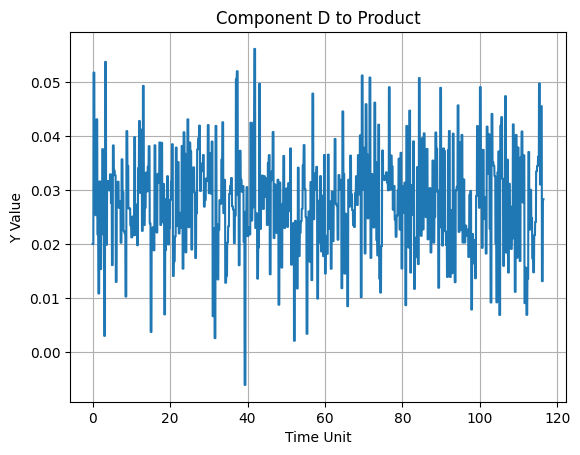

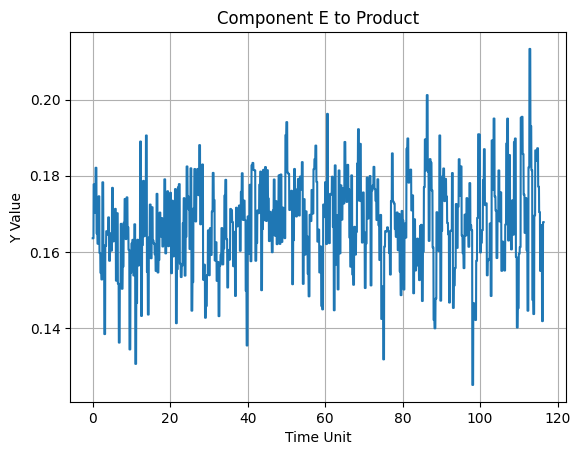

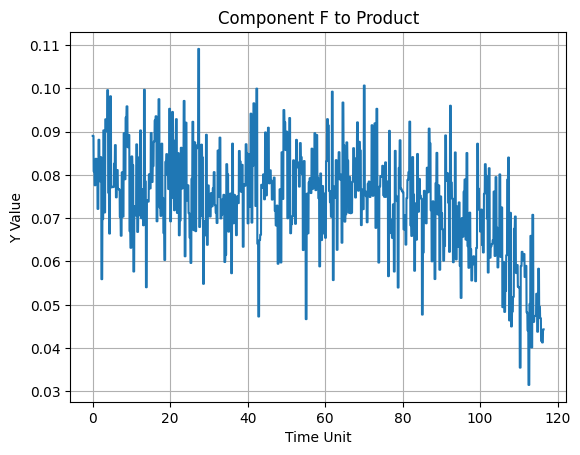

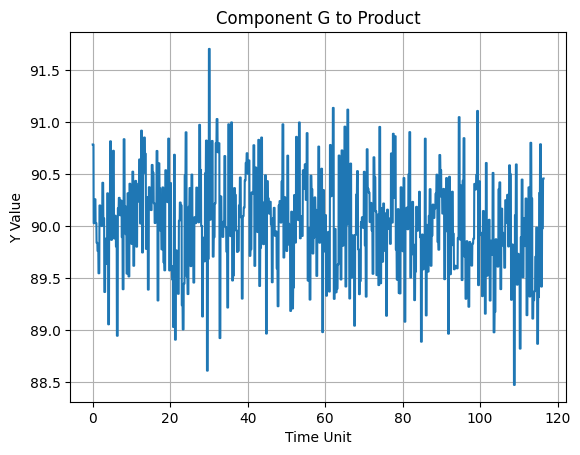

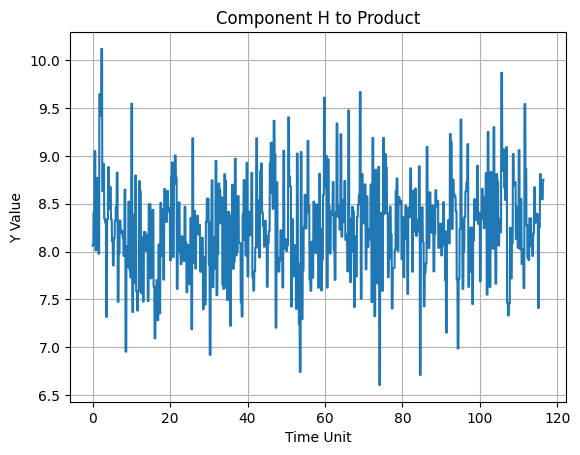

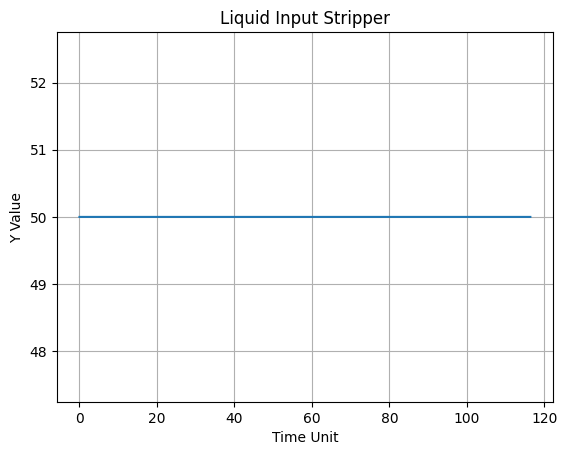

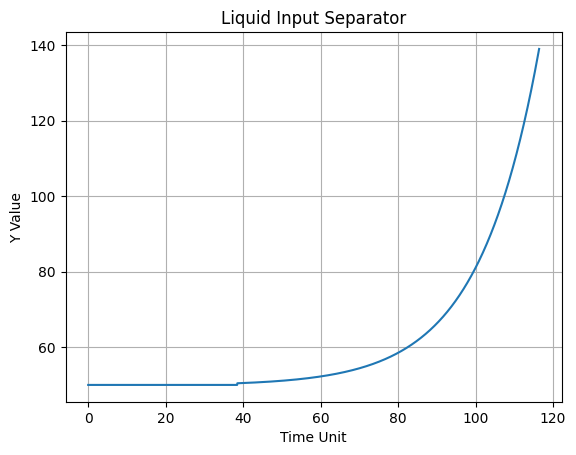

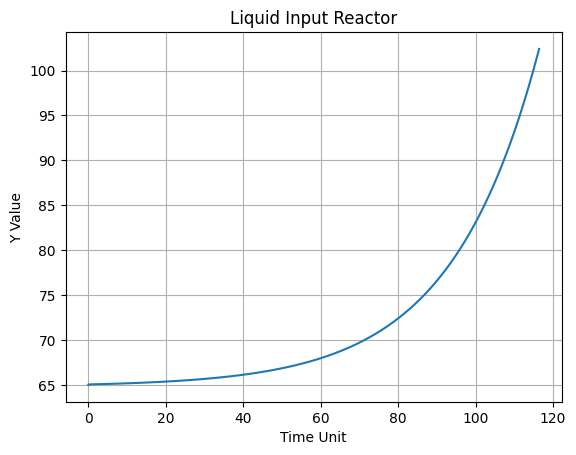

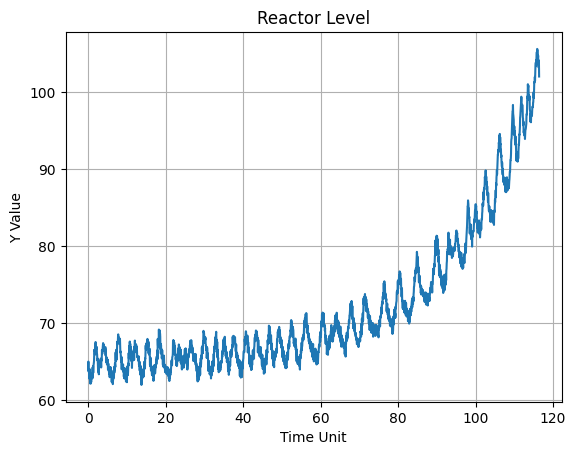

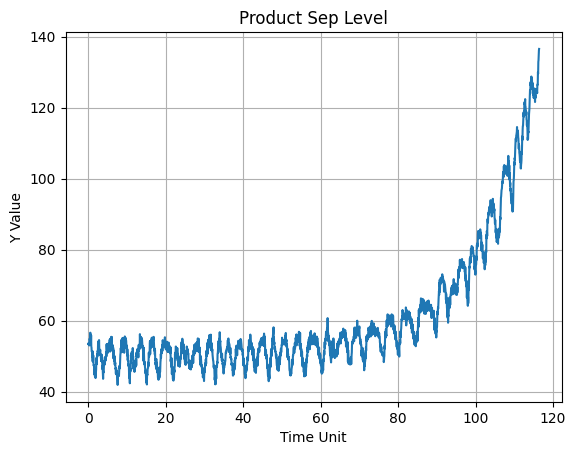

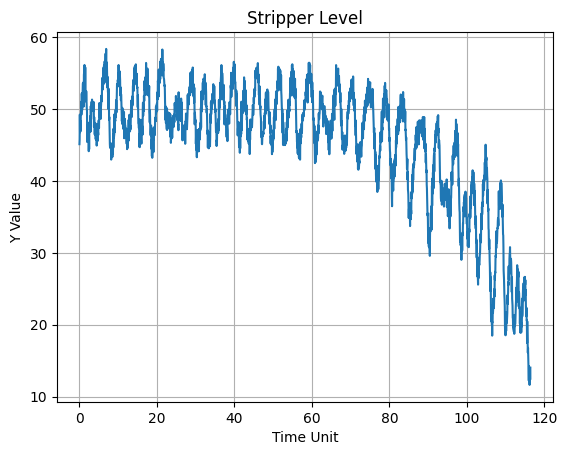

In [4]:
# curId will be from 1 to 100
drawData    = rawData[drawID]
drawTime    = time[drawID]
drawRUL     = rulLabel[drawID]

# print(drawData.shape)
# print(drawTime.shape)

for idx,feature in enumerate(headline):
    plot.draw2D(xCoor=drawTime[:,:],
                yCoor=drawData[:,idx],
                title= feature)  

#### Draw degradation

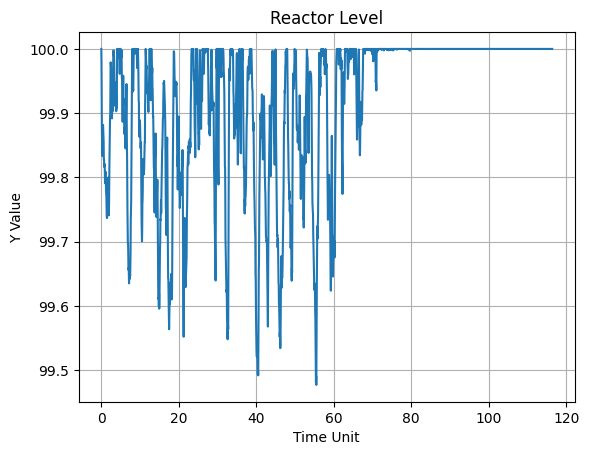

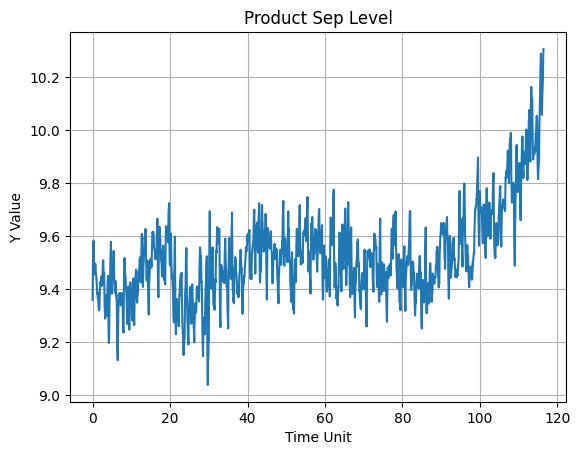

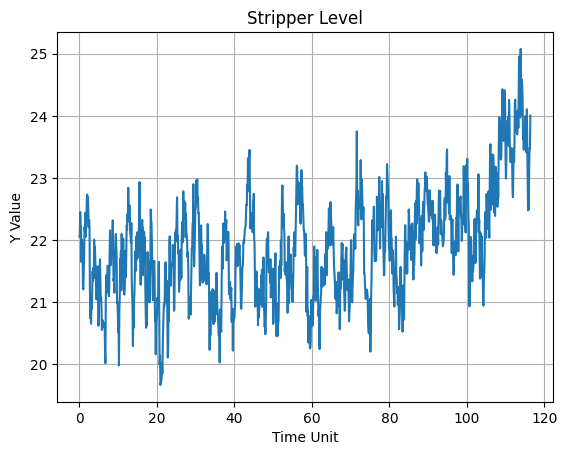

In [5]:
# curId will be from 1 to 100
drawData    = rawData[drawID]
drawTime    = time[drawID]
drawRUL     = rulLabel[drawID]

# print(drawData.shape)
# print(drawTime.shape)

for idx,feature in enumerate(preData.degraLiq):
    plot.draw2D(xCoor=drawTime[:,:],
                yCoor=drawData[:,idx],
                title= feature)  

### b. Clean the data 

In [6]:
# cleanData           = preData.cleanData(rawData,
#                                         getMovingAverage    =   True,
#                                         flipToDown          =   True)

### Draw cleaned data

In [7]:
# drawCleanData = cleanData[drawID]
# for idx,feature in enumerate(headline):
#     plot.draw2D(xCoor   = drawTime[:,:],
#                 yCoor   = drawCleanData[:,idx],
#                 title   = feature)  
    
# print("display finished")

### d. Normalize the data

In [8]:
norData                     = preData.normalizeData(rawData)                # Normalize the data

theCaseData,time,           = preData.getTheCase(   theCase    = case,
                                                    data       = norData,
                                                    time       = time)

Process:70739||2024-03-18 00:56:14,295-INFO [preProcessingData.py:normalizeData():273]:Normalizing the data ...
/home/duc/Documents/1stphdjournal_lstm/cnnVAE/preProcessingData.py:305: RuntimeWarning: invalid value encountered in divide
  norData = [(eachTraject - minEachFeature) / (maxEachFeature - minEachFeature) for eachTraject in rawData]


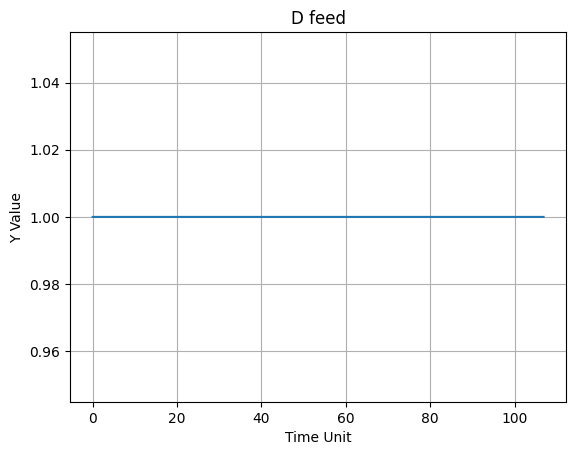

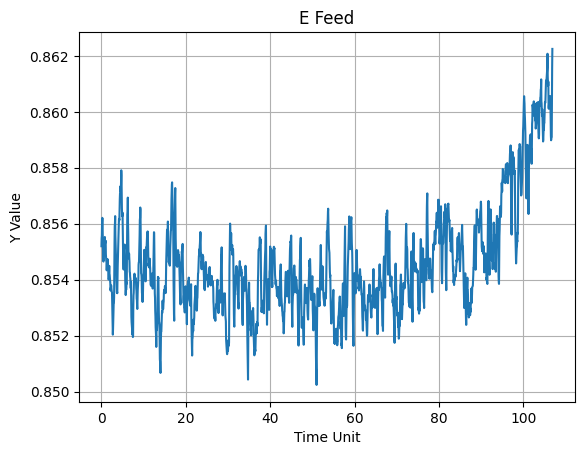

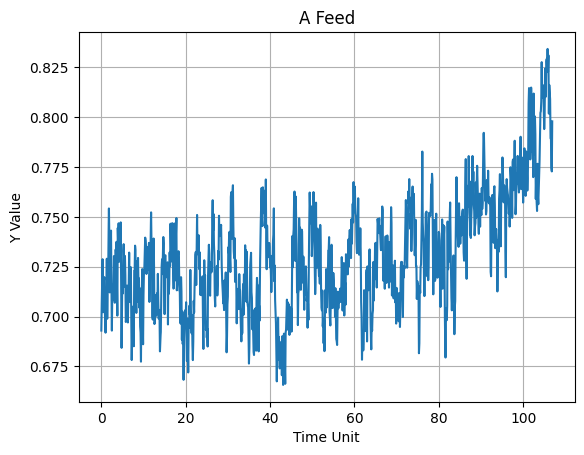

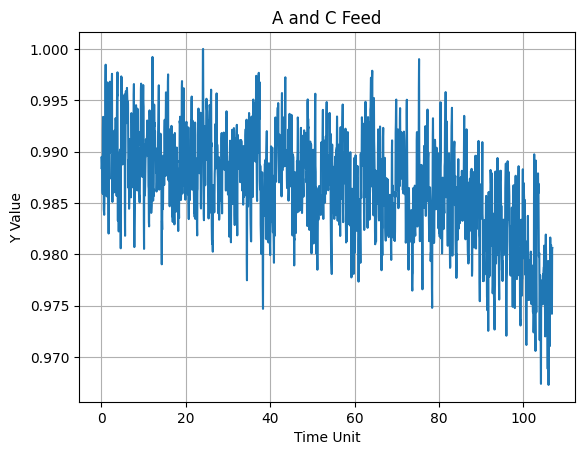

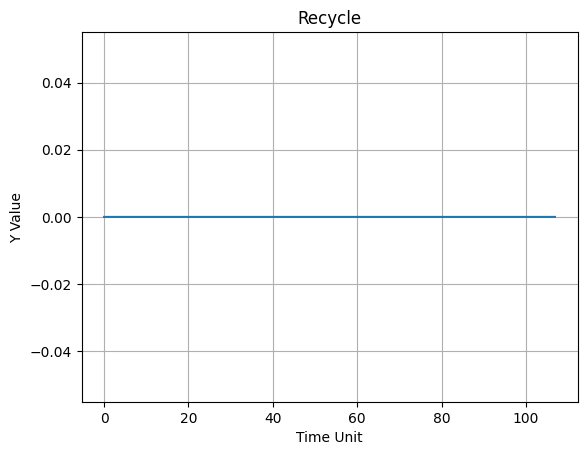

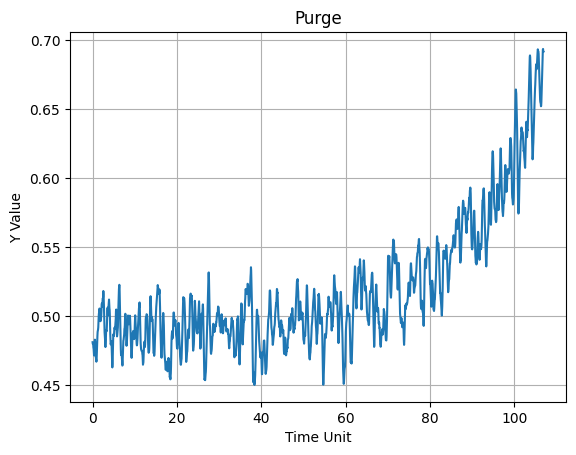

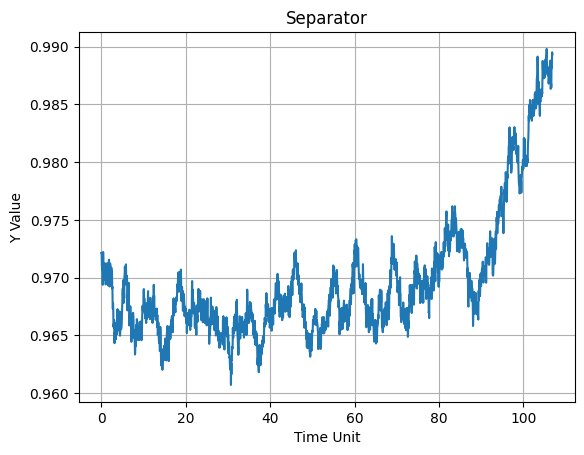

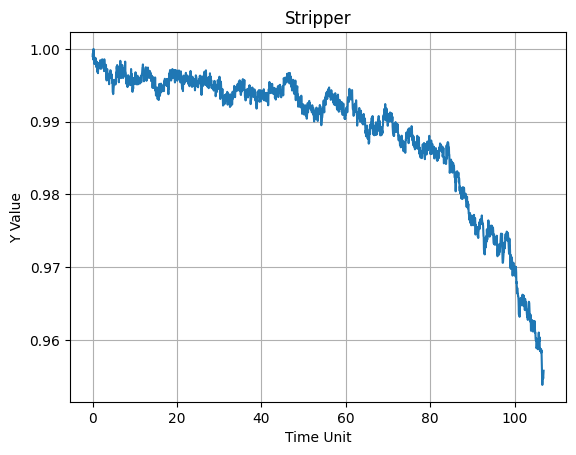

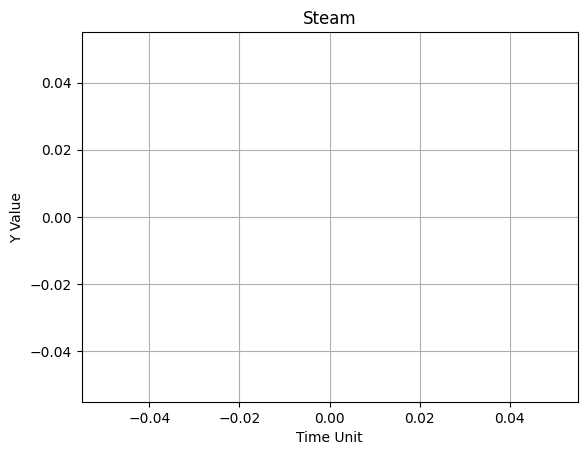

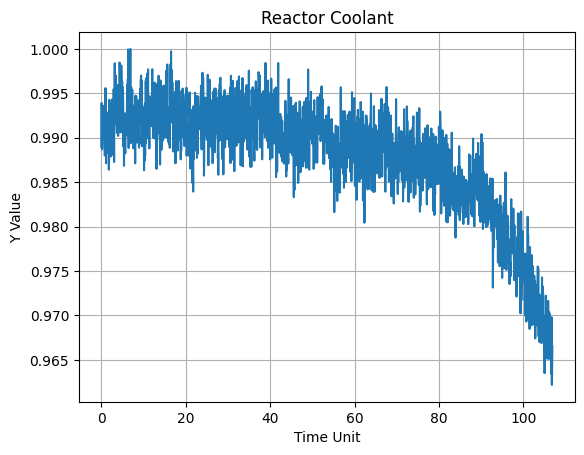

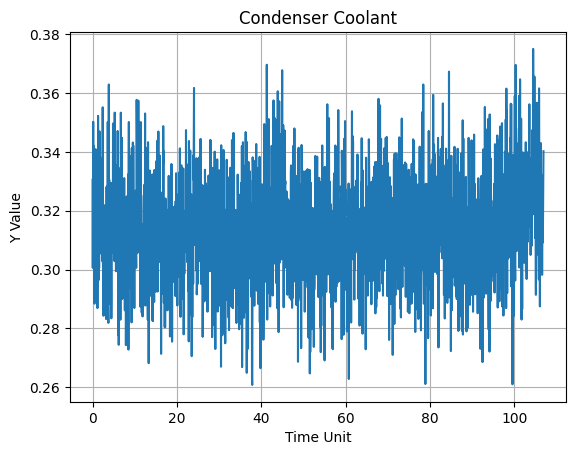

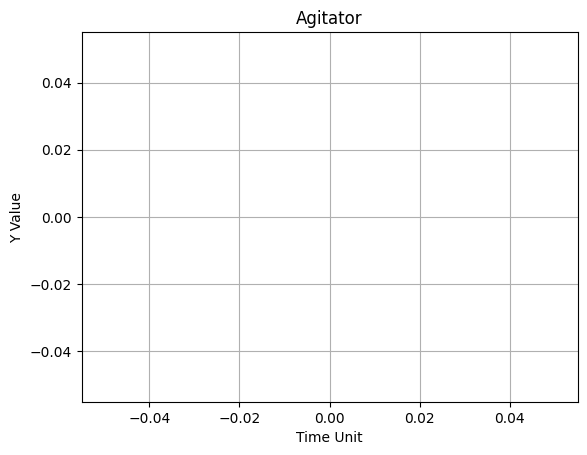

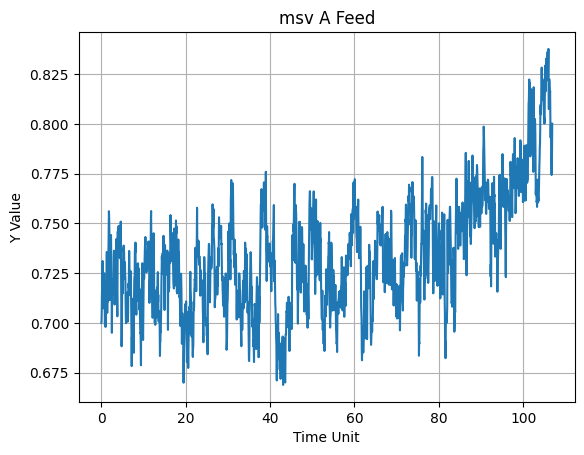

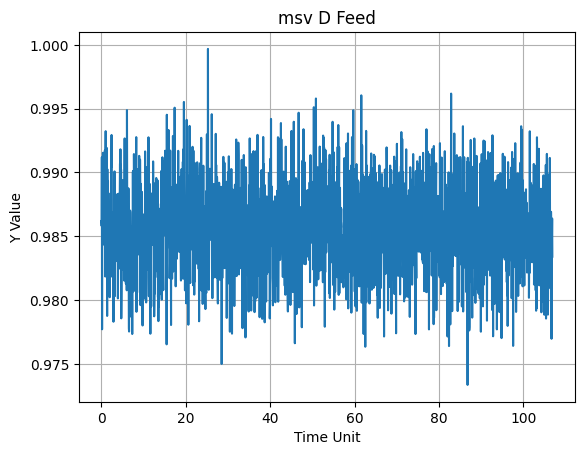

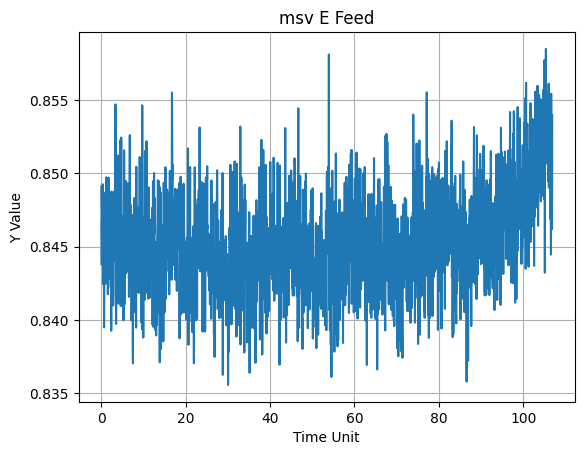

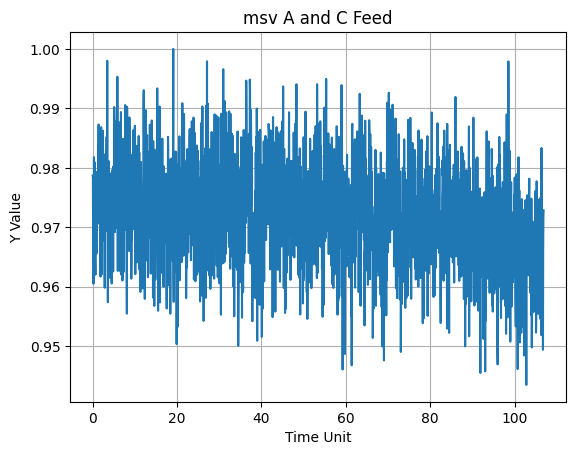

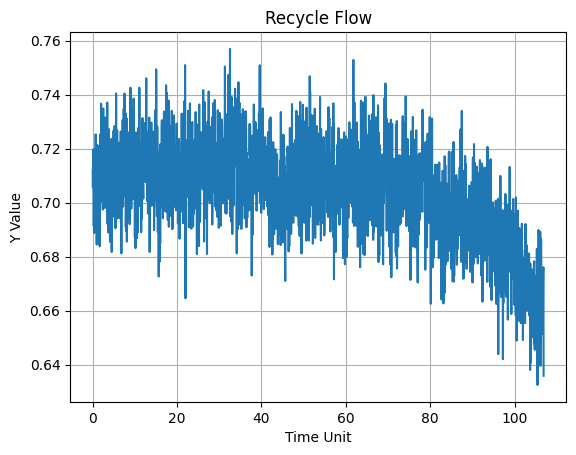

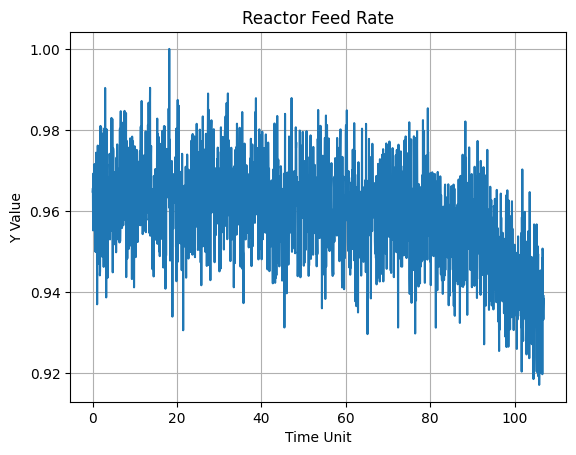

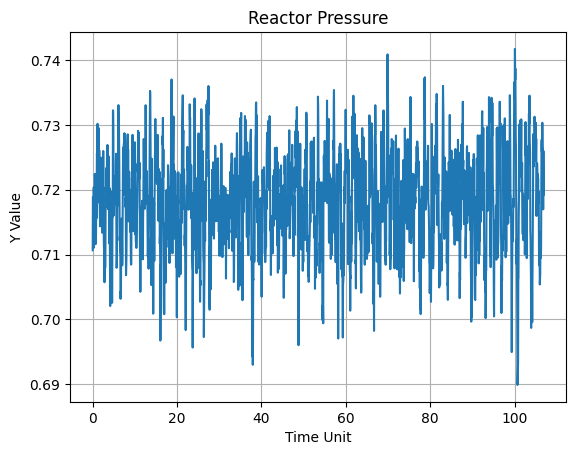

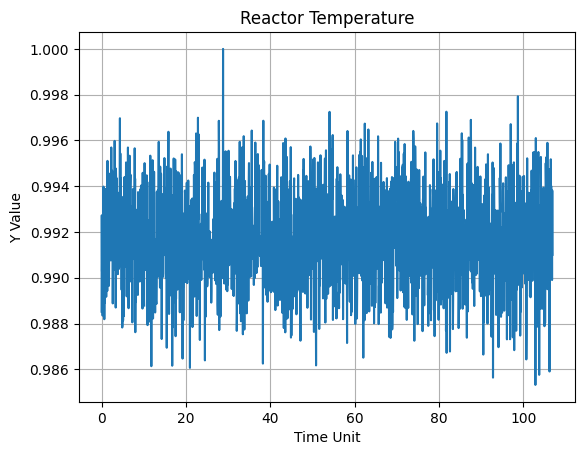

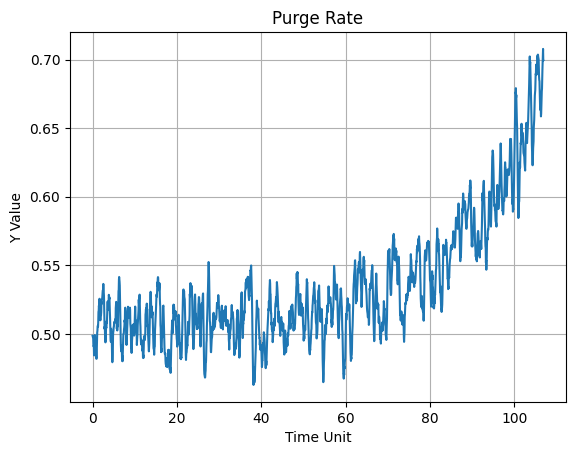

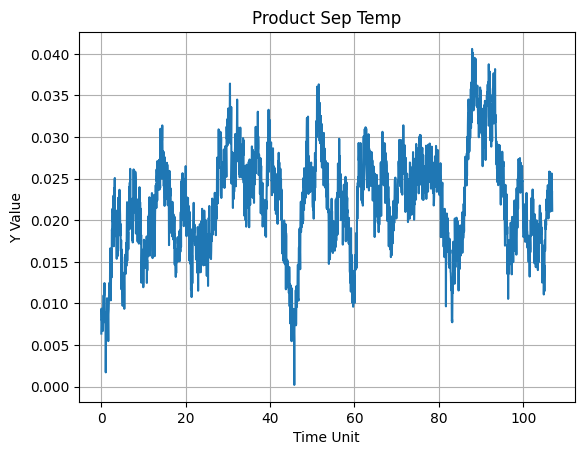

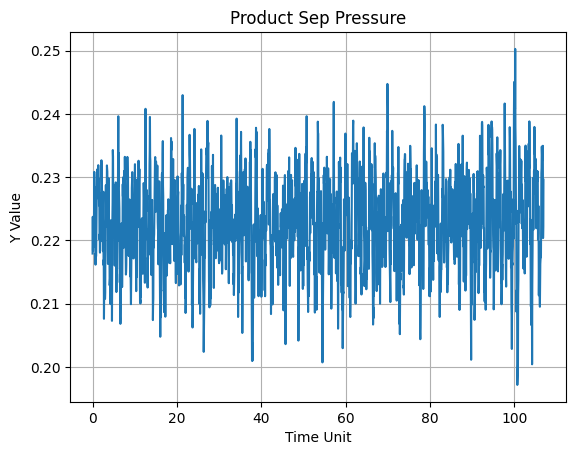

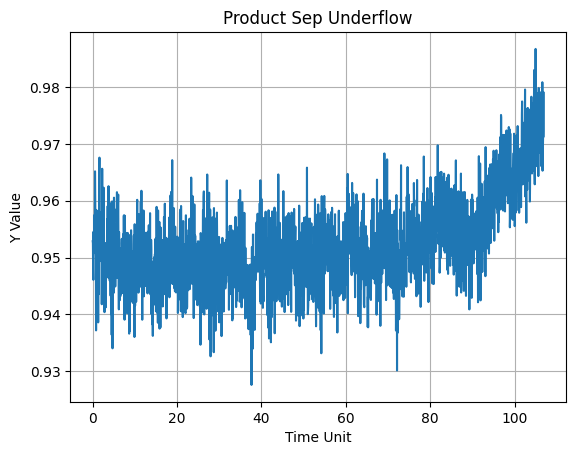

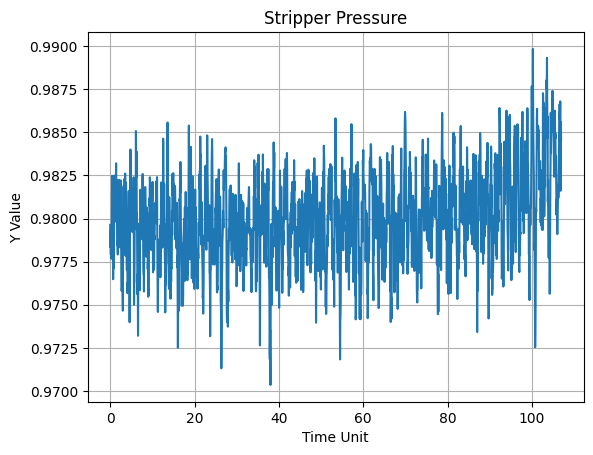

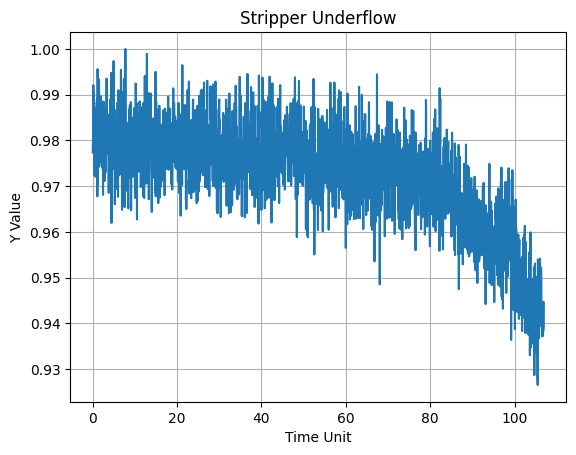

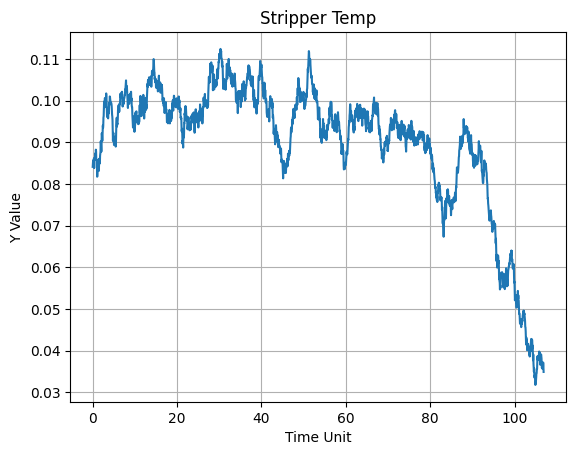

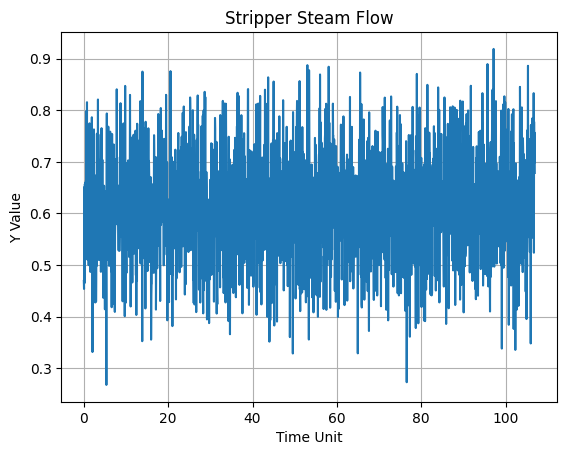

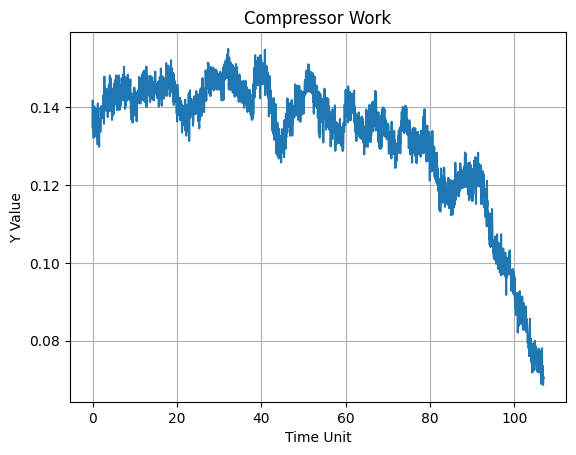

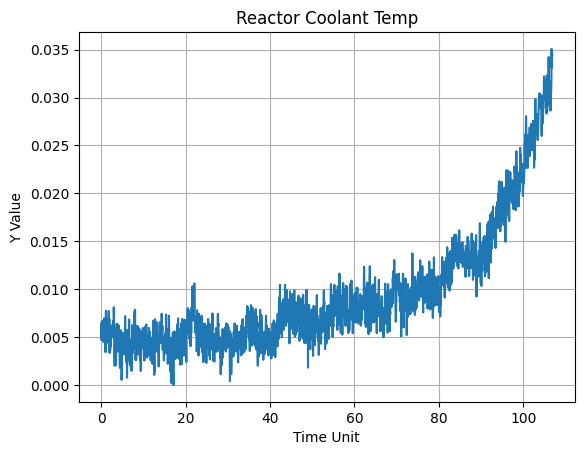

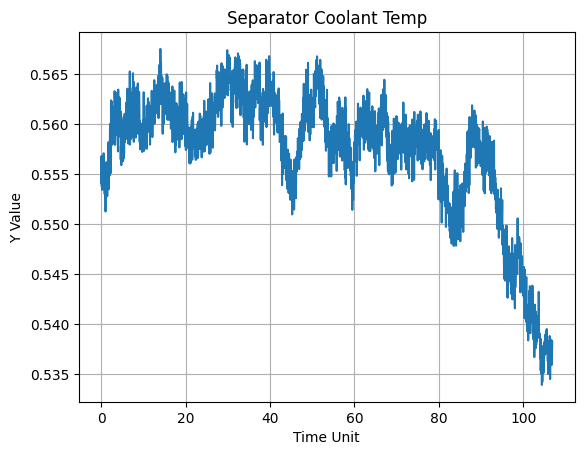

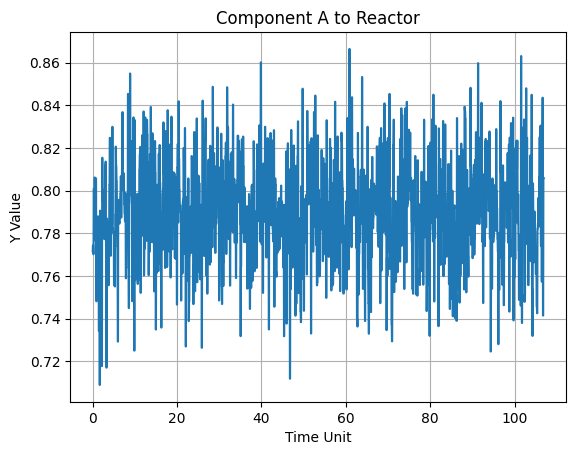

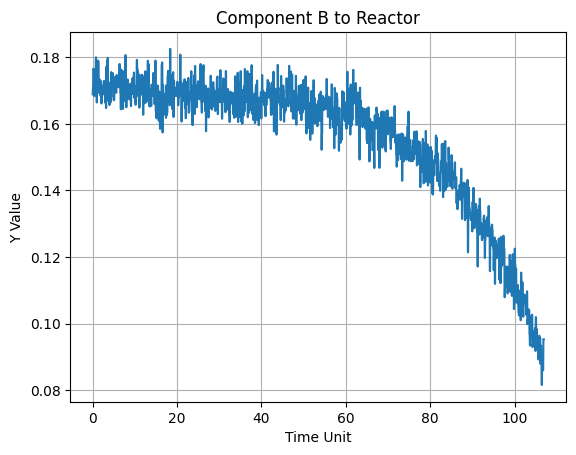

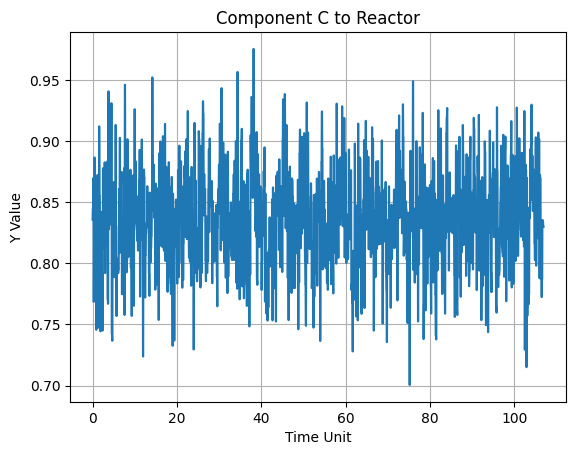

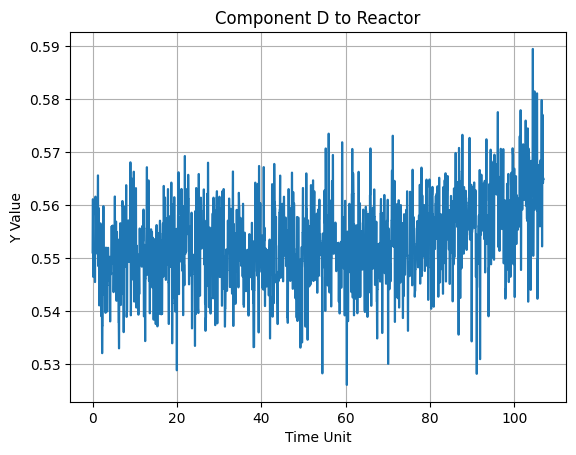

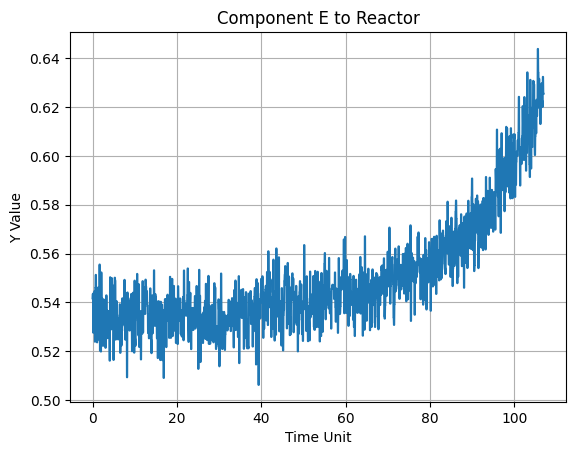

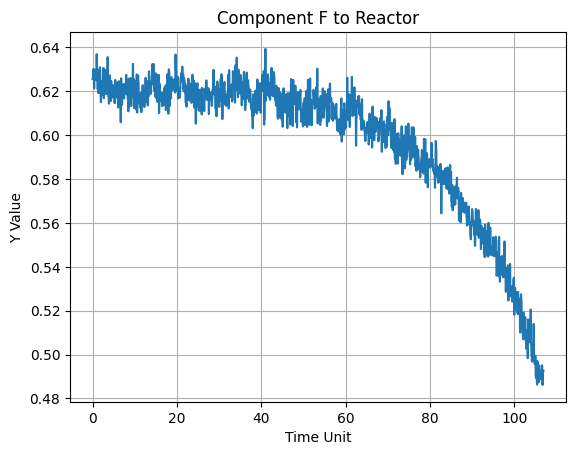

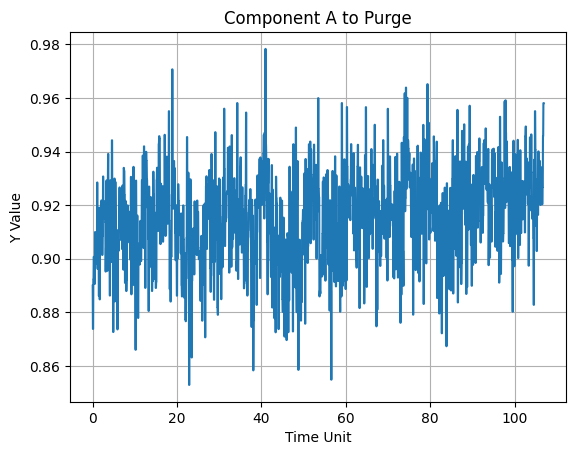

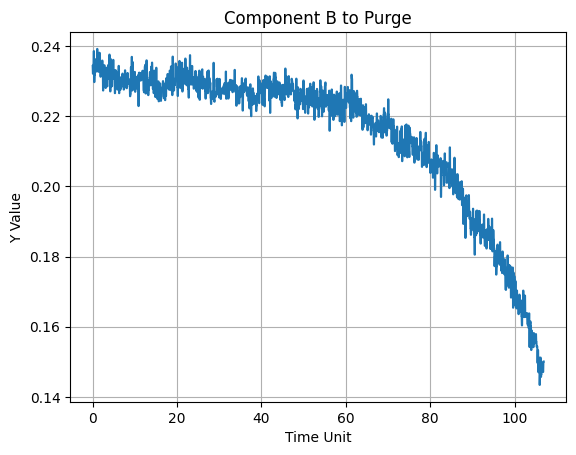

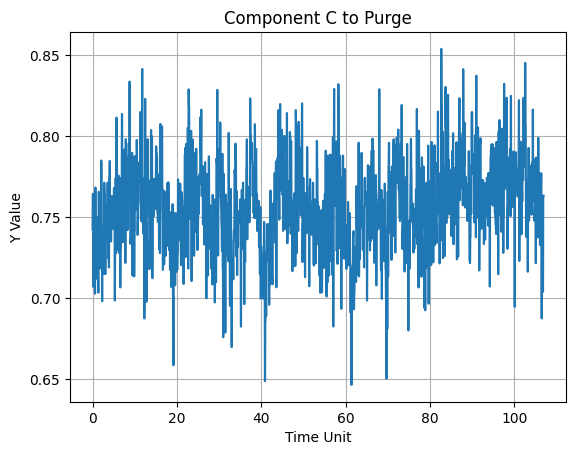

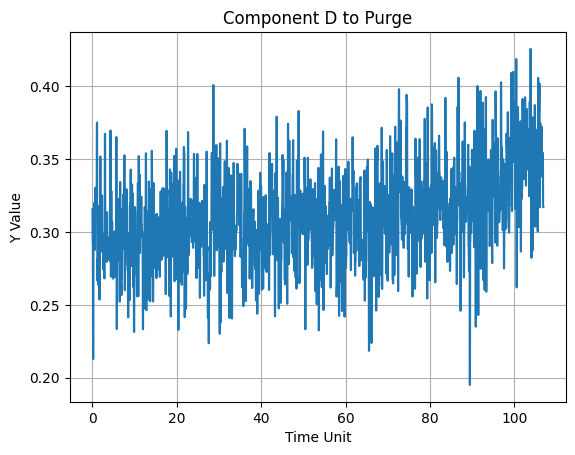

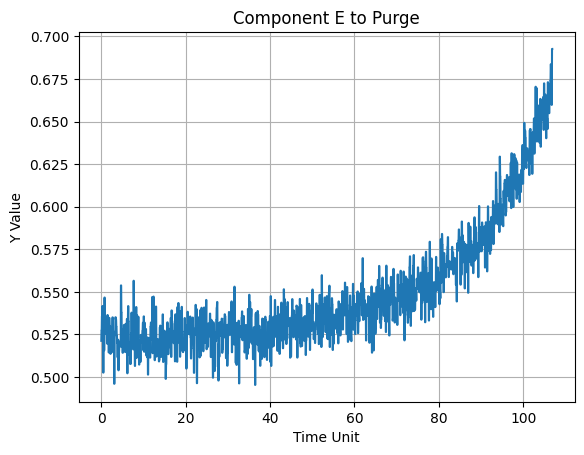

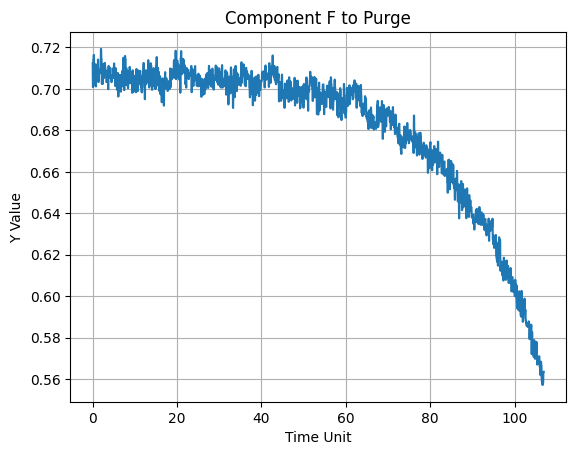

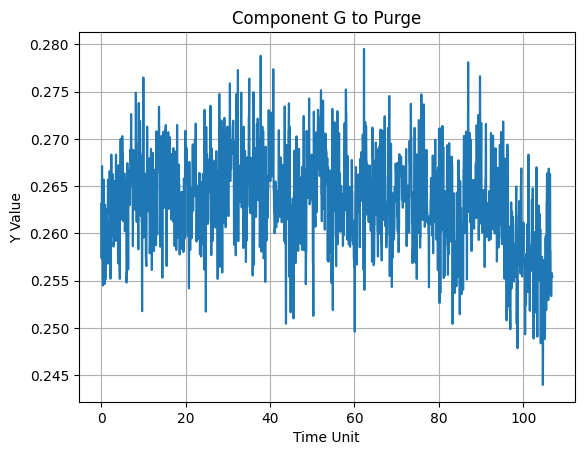

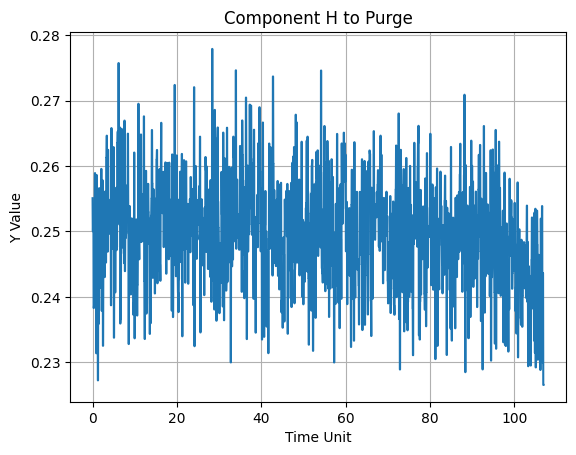

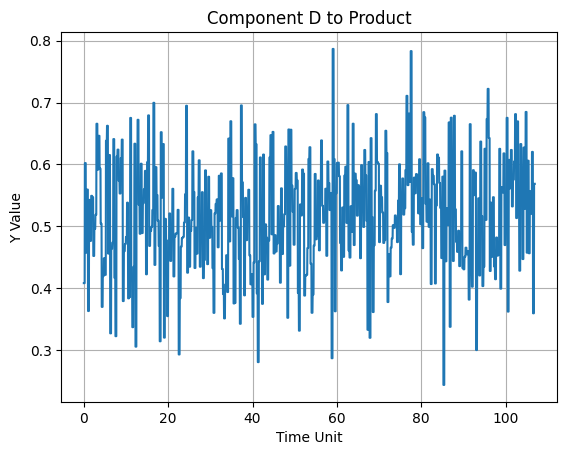

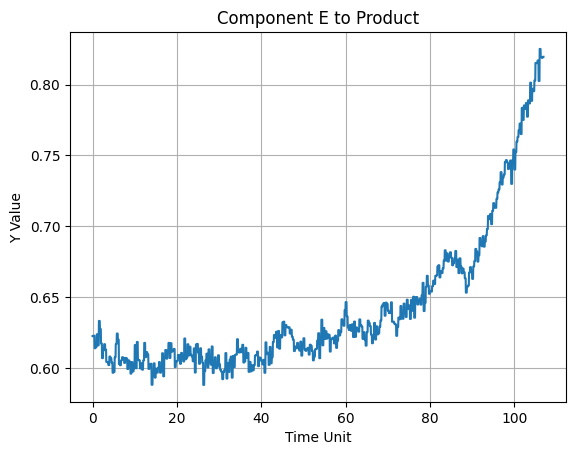

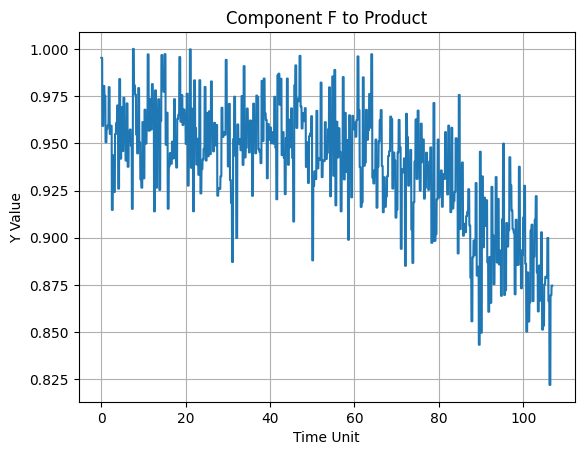

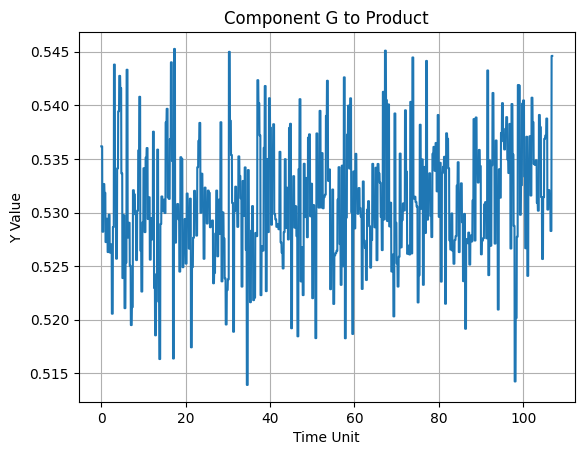

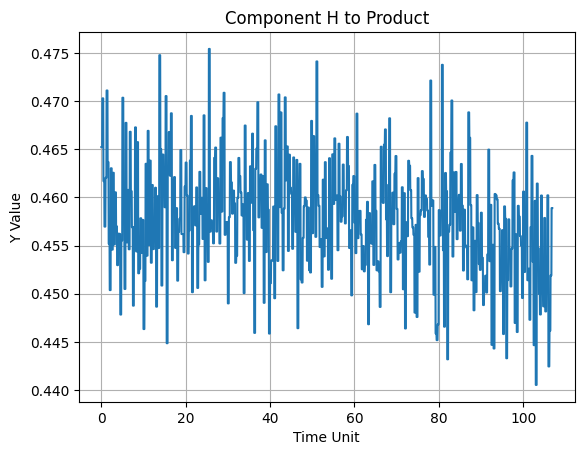

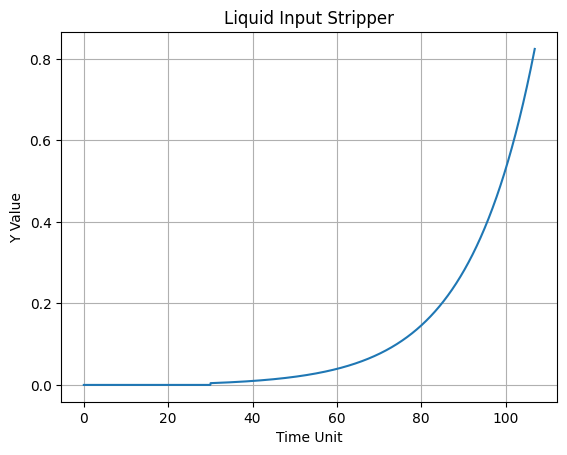

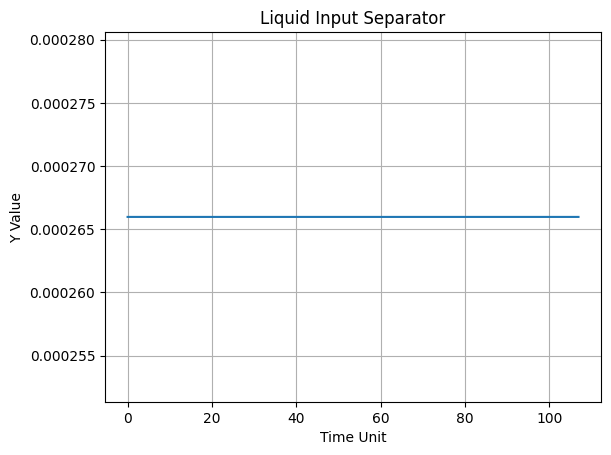

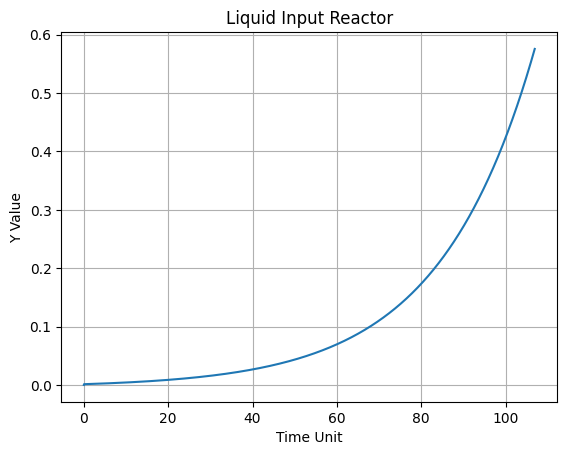

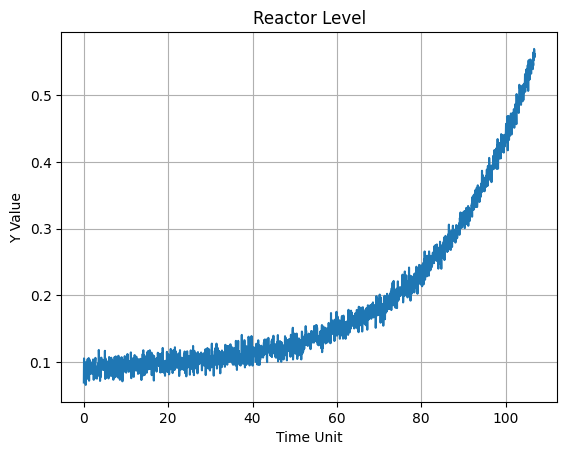

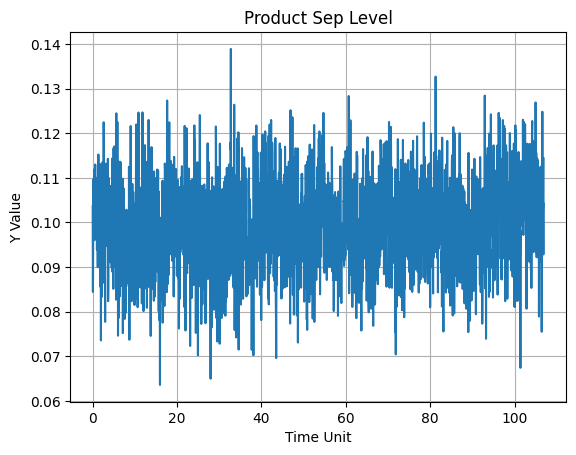

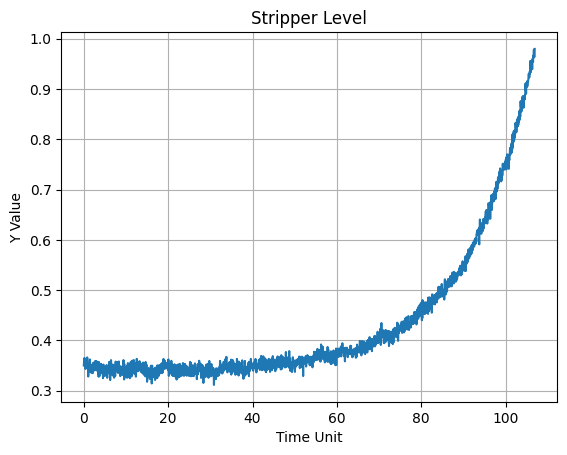

In [9]:
drawNormal = theCaseData[drawID]
drawTime    = time[drawID]
for idx,feature in enumerate(headline):
    plot.draw2D(xCoor=drawTime[:,:],
                yCoor=drawNormal[:,idx],
                title= feature)  

### Normalize and clean label

In [10]:

normDegra           = preData.normalLabel(degra)                # Normalize the data



# cleanedDegra    = preData.cleanData(normDegra,
#                                     getMovingAverage = True,
#                                     flipToDown       = True)  

Process:70739||2024-03-18 00:56:17,899-INFO [preProcessingData.py:normalLabel():312]:Normalizing the label ...


### Draw degradation

ValueError: x and y must have same first dimension, but have shapes (2139, 1) and (2329,)

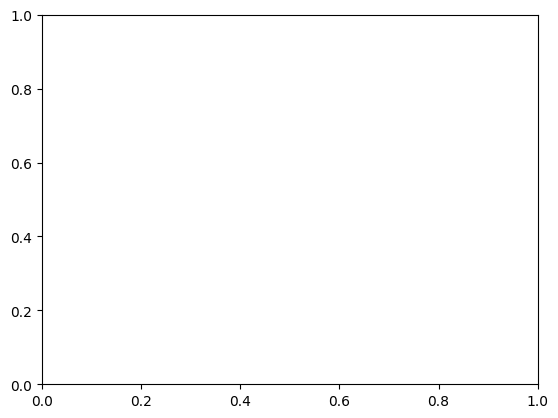

In [11]:
drawNormalDegra = normDegra[drawID]

for idx,feature in enumerate(degraHeadline):
    plot.draw2D(xCoor=drawTime[:,:],
                yCoor=drawNormalDegra[:,idx],
                title= feature)  

In [ ]:
labelData = rulLabel[drawID]

plot.draw2D(  xCoor= drawTime[:,:],
            yCoor= labelData,
            title= "RUL of " + component)

### f. Split into train and validation data

In [ ]:
trainXY,valXY       = preData.splitTrainVal(norData,rulLabel)       # Split data and label into train and validation dataeset


### g. Split into each sequence

In [ ]:
seqTrainXY          = preData.splitAllDataIntoSequences(trainXY)
seqValXY            = preData.splitAllDataIntoSequences(valXY)  

print(seqTrainXY[0].shape,seqTrainXY[1].shape)
print(seqTrainXY[0][2011][:,0])

### h. Visualize the tensor data

In [ ]:

# Creating an array from 1 to 3000
#time = np.arange(1, 10)
# t= 0:200
# plot.draw1D(yCoor=seqTrainXY[1][0:t])
plot.draw1D(yCoor=seqTrainXY[0][2011][:,3])
            


# 4. Model and training

### To tensor

In [ ]:
tensorTrainXY       = data.TensorDataset(seqTrainXY[0],seqTrainXY[1])
tensorValXY         = data.TensorDataset(seqValXY[0],seqValXY[1])

In [ ]:
train_loader = data.DataLoader(tensorTrainXY,
                                batch_size  =   config.batch_size,
                                shuffle     =   False, 
                                num_workers =   config.num_workers)
        
val_loader = data.DataLoader(  tensorValXY, 
                                batch_size  =   config.val_batch_size, 
                                shuffle     =   False, 
                                num_workers =   config.num_workers)

### Declare model and parameters

In [ ]:
from torchsummary import summary
# ------------------------
# Declare model and parameters
# ------------------------
model      = TEPsModel()        

optimizer  = torch.optim.Adam( params=model.parameters(), 
                                    lr=0.01, 
                                    weight_decay=1e-4)

criterion = nn.MSELoss()        #L1Loss, MSELOSS

scheduler = torch.optim.lr_scheduler.StepLR(optimizer, 
                                            step_size=100, 
                                            gamma=0.1)

model = nn.DataParallel(model) if (torch.cuda.device_count() > 1) else model
model.to(device)
model.eval()
# summary(model,input_size=[128,18],batch_size=64)

### Training function

In [ ]:

#======================================
# Training
#--------------------------------------
def training(self,epoch):
    vis_loss        = 0.0
    running_loss    = 0.0
    cur_itrs        = 0
    
    self.model.train()
    for idx,(features,labels) in enumerate(self.train_loader):
        
        cur_itrs += 1
        features    = features.to(self.device,dtype=torch.float32)
        labels      = labels.to(self.device,dtype=torch.float32)
        
        #-------------------------------
        # Compute forward pass and loss
        #-------------------------------
        rulOutput,_,_,_  = self.model(features)
        # print(output)
        # rulOutput = unsqueze(rulOutput)
        
        # print(labels.shape)
        # print(rulOutput.shape)
        loss    = self.criterion(rulOutput,labels)
        # print(loss)
        
        #-------------------------------
        # Compute gradient and do optimize step
        #-------------------------------
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        
        #-------------------------------
        # measure accuracy and record loss 
        #-------------------------------
        # print(labels.size(0))
        vis_loss         += loss.item()                     # Get the average loss of the current batch
        running_loss     += loss.item()*features.size(0)    # Get the total loss of current batch
        
        self.scheduler.step()
        
        # -------------------------------
        # Calculate and print loss after
        # each 10 epochs
        # -------------------------------
        if (cur_itrs) %10 == 0:
            vis_loss /= 10
            print("Epoch %d, Itrs %d/%d, Training Loss=%f" %
                    (epoch, cur_itrs, self.num_train_data/self.batch_size, vis_loss))
            vis_loss = 0.0
    
    # -------------------------------
    # Get the average loss for each 
    # epoch, len(train_loader) show 
    # the number of batch in dataset
    # -------------------------------
    epoch_loss = running_loss/len(self.train_loader)          
    print('{} Epoch {}, Training Epoch loss {}'.format(datetime.datetime.now(), 
                                                    epoch,
                                                    epoch_loss))
    if self.visualize:
        self.vis.vis_scalar(title       = 'Loss',
                            line_name   = 'train',
                            x_coor      = epoch,
                            y_coor      = epoch_loss,
                            )
    
    
#======================================
# Validation
#--------------------------------------
def validation(self,epoch):
    running_loss = 0
    self.model.eval()
    tbar = tqdm((self.val_loader),desc="Validation")
    with torch.no_grad():
        for idx,(features,labels) in enumerate(tbar):
            features    = features.to(self.device, dtype=torch.float32)
            labels      = labels.to(self.device, dtype=torch.float32)
            rulOutput,_,_,_     = self.model(features)
            loss        = self.criterion(rulOutput,labels)
            
            running_loss  += loss.item()*features.size(0)
            
            
        epoch_loss = running_loss/len(self.val_loader)
            

    print('{} Epoch {}, Validation Epoch loss {}'.format(datetime.datetime.now(), 
                                                        epoch,  
                                                        epoch_loss))
    
    
    if self.visualize:
        self.vis.vis_scalar(title = 'Loss', line_name = 'val', x_coor = epoch, y_coor= epoch_loss)

    return epoch_loss

            
                
#======================================
# Save checkpoint
#--------------------------------------
def save_ckpt(self,epoch=None,path = "checkpoints/ckpt.pth", best_score=0):
    if not os.path.exists("checkpoints/"):
        os.makedirs("checkpoints/")
    torch.save({
        "cur_epoch": epoch,
        "model_state": self.model.state_dict(),
        "optimizer_state": self.optimizer.state_dict(),
        "scheduler_state": self.scheduler.state_dict(),
        "best_score": best_score,
    }, path)
    print("Model saved as %s" % path)
    
    
#======================================
# Train a part of model
#--------------------------------------    
# def freeze_at(self,frozen_module):
#     for name,parameter in self.model.named_parameters():
#         parameter.requires_grad = True  # train all layers
#         if frozen_module in name:
#             print('freezing %s' % name)
#             parameter.requires_grad = False
#     print("Freezing {} was successfull!".format(frozen_module))

### Main function to run

In [ ]:
#=====================================
#      MAIN FUNCTION
#=====================================    
def main():
   
    best_score  = 0
    
    for epoch in range(1,config.n_epochs+1):
        training(epoch)
        epoch_loss = validation(epoch)
        save_ckpt(epoch,path= last_ckpt,best_score= best_score)

        if epoch_loss < best_score:
            best_score = epoch_loss
            save_ckpt(epoch,path= best_ckpt ,best_score= best_score)
            

if __name__ == '__main__':
    main()